<h1>Assignment 02: Feature Extraction with VGG16 (Model 2)</h1>

<h2>1. Business understanding</h2>

Our main goal is to create a model with our own image dataset and experiment with three different approaches for training the models and compare which of these approaches works the best.

1. <b>Custom Convolutional Neural Network (CNN)</b> built from scratch using our own dataset.
2. <b>Feature Extraction using a pre-trained VGG16 model</b>, training only a custom classifier on top of the extracted features.
3. <b>Fine-tuned pre-trained model</b> with frozen lower layers and adapted upper layers.

This notebook contains the approaches and experiments of the model number two. Report and comparisons are done in a separate notebook.



<h2>2. Data understanding</h2>

In [10]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

rps_dir = pathlib.Path("./rps") #directory with all data

for folder in sorted(rps_dir.rglob("*")):
    if folder.is_dir():
        image_files = list(folder.glob("*.jpg")) + list(folder.glob("*.png")) + list(folder.glob("*.jpeg"))
        rel_path = folder.relative_to(rps_dir)
        print(f"Path: {rel_path} | Amount of images: {len(image_files)}")

Path: test | Amount of images: 0
Path: test\paper | Amount of images: 19
Path: test\rock | Amount of images: 17
Path: test\scissors | Amount of images: 17
Path: train | Amount of images: 0
Path: train\paper | Amount of images: 63
Path: train\rock | Amount of images: 64
Path: train\scissors | Amount of images: 64
Path: validation | Amount of images: 0
Path: validation\paper | Amount of images: 18
Path: validation\rock | Amount of images: 17
Path: validation\scissors | Amount of images: 18


Amout of images in dataset:

* **Train Images**:
  * Paper: 63 images
  * Rock: 64 images
  * Scissors: images *(total of 191 images)*
* **Validation Images**:
  * Paper: 18 images
  * Rock: 17 images
  * Scissors: 18 images *(total of 53 images)*
* **Test Images**:
  * Paper: 19 images
  * Rock: 17 images
  * Scissors: 17 images *(total of  53 images)*

This shows that used dataset is really small with less than 300 images.

In [124]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices())

2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [125]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3))
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_40 (InputLayer)     │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 180, 180, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 180, 180, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 90, 90, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 90, 90, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 45, 45, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 45, 45, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 22, 22, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 22, 22, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 22, 22, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 11, 11, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 11, 11, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 5, 5, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

As seen above, the VGG16 convolutional base is a very deep network with approximately 14 million parameters.

<h2>3. Data preparation</h2>

Before training the model data preparation is done. The two main steps are loading the datasets into the notebook for training, evaluating and testing the model. Next really important step is to do <i>feature extraction</i>, our prepared data goes through VGG16 pre-trained model, the results are extracted and used to train our own model.

<h3>3.1 Load and Prepare Datasets</h3>

In [13]:
#SUPPORTS FORMATS: JPEG (.jpg, .jpeg), PNG (.png), BMP (.bmp) AND GIF (.gif)

train_dataset = image_dataset_from_directory(
    rps_dir / "train",
    image_size = (180, 180),
    batch_size = 32)

validation_dataset = image_dataset_from_directory(
    rps_dir / "validation",
    image_size = (180, 180),
    batch_size = 32)

test_dataset = image_dataset_from_directory(
    rps_dir / "test",
    image_size = (180, 180),
    batch_size = 32,
    shuffle=False)

Found 191 files belonging to 3 classes.
Found 53 files belonging to 3 classes.
Found 53 files belonging to 3 classes.


<h4>Folder Configuration and Loading Dataset</h4>

`train_dataset = image_dataset_from_directory(rps_dir / "train", image_size = (180, 180), batch_size = 32)`

`rps_dir / "train"` <br/>
- Makes a search in the directory.
- Keras makes assumption that there are subfolders for each class, which there are.
    - Rock
    - Paper
    - Scissors
- Keras recognizes each subfolder as its own separate class.

`image_size` <br/>
- Resizes each pictures to be automatically 180x180 pixels.
- <b>This is a really important step, because now each image has exactly the same size when feeded to model.</b>

`batch_size` <br/>
- Configures the amount of data is feeded to the model. In this models case, it is feeded in 32 batches. (This speeds the training)
  
<h4>Separate dataset in three</h4>

The same process is repeated on three different folders, `train_dataset`, `validation dataset` & `test_dataset`.

- `train_dataset`: Training data, approximately 80% of the images with which the model is trained.
- `validation_dataset`: Validation data, approximately 10% of the images, this is used for observing if the models start to overfit while being trained.
- `test_dataset`: Test data, approximately 10% of the images, this is used to test the final model. This images are only used when the model trained and overfitting with validation data is adjusted.

This is a great way to automatize importing images and classifying them.

<h3>3.2 Feature Extraction</h3>

It takes a lot of resources to compute the VGG16 convolutional features every time we train the model, so it is wise to run our images through VGG16 once and save the results in memory. This way, we can train our own model using the features extracted by VGG16, which makes the training process extremely fast.

In [14]:
import numpy as np

def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

print('\nTrain shape:',train_features.shape, '\nValidation shape', val_features.shape,'\nTest shape', test_features.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

Train shape: (191, 5, 5, 512) 
Validation shape (53, 5, 5, 512) 
Test shape (53, 5, 5, 512)


# <h4>What is the output?</h4>

The results show that our Rock-Paper-Scissors data is run throught the VGG16 model. It took approximately <b>1-3 seconds to run one batch through one convolutional layer</b>.

<b>Output</b> <br/>
`(AMOUNT_OF_IMAGES_IN_OUR_DATASET, NEW_WIDTH, NEW_LENGHT, DEPTH)`

After running our 191 training images through the VGG16 convolutional base, output is a shape (191, 5, 5, 512). Each feature map has a size of 5x5 and a depth of 512 channels. <b>The depth channel contains visual data like <i>vertical lines, curves, textures, and color patterns</i> extracted from the original images</b>.

---

<h4>Feature Extraction Function</h4>

`get_features_and_labels(dataset)` <br/>

- This function takes a dataset as a paremeter (e.g. <i>train_dataset</i>) and goes trought the images in batches.

`preprocess_input(images)` <br/>

- Adjusts image values and colors to the format that VGG16 is using.

`conv_base.predict(preprocessed_images)` <br/>

- This feeds images throung the VGG16 layers. These layers do not learn anything new, it works more like an filter that formats our images to a specific feature maps. In this case ( ... , 5, 5 512).

`np.concatenate(...)` <br/>

- This collects all the results together and assembles it as one NumPy -table with <i>all_features</i> and <i>all_labels</i>.

This function is used three times, ones on each of our datasets `train_dataset`, `validation_dataset` & `test_dataset`.

<h2>4. Modeling</h2>

The idea is to experiment and create three models with different optimizers and layer adjustments to find the most suitable approach. The biggest problem is that our own dataset is very small. Therefore, it will be a challenge to achieve good generalization and avoid overfitting altogether.

<h4>Training Model #1</h4>

In [74]:
#MODEL 01

model_01 = keras.Sequential([

#input
keras.Input(shape=(5, 5, 512)),

#hidden
layers.Flatten(),
layers.Dense(256, activation="relu"),
layers.Dropout(0.5),

#output
layers.Dense(3, activation="softmax")
])

model_01.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

history_01 = model_01.fit(
    train_features, train_labels,
    epochs=100,
    validation_data=(val_features, val_labels))

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 159ms/step - accuracy: 0.4869 - loss: 31.9565 - val_accuracy: 0.5849 - val_loss: 5.0187
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8534 - loss: 1.7583 - val_accuracy: 0.5283 - val_loss: 4.6899
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8377 - loss: 1.4699 - val_accuracy: 0.6226 - val_loss: 3.6093
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8796 - loss: 1.0413 - val_accuracy: 0.6792 - val_loss: 3.7219
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9581 - loss: 0.2620 - val_accuracy: 0.7170 - val_loss: 3.3691
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.9634 - loss: 0.3564 - val_accuracy: 0.5472 - val_loss: 4.4781
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9634 - loss: 0.3371 - val_accuracy: 0.7358 - val_loss: 3.7956
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9791 - loss: 0.2072 - val_accuracy: 0.6604 - val_los

<h4>Results: Model #1</h4>

- Accuracy $\approx$100%
- Loss $\approx$0
- Validation accuracy $\approx$72%
- Validation loss $\approx$7.3

---

<h4>Training Model #2</h4>

In [75]:
#MODEL 02

model_02 = keras.Sequential([

#input
keras.Input(shape=(5, 5, 512)),

#hidden
layers.GlobalAveragePooling2D(),
layers.Dense(256, activation="relu"),
layers.Dropout(0.5),

#output
layers.Dense(3, activation="softmax")
])

model_02.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="Adam",
    metrics=["accuracy"]
)

history_02 = model_02.fit(
    train_features, train_labels,
    epochs=100,
    validation_data=(val_features, val_labels))

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step - accuracy: 0.3455 - loss: 3.0903 - val_accuracy: 0.3208 - val_loss: 3.6546
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5550 - loss: 1.6748 - val_accuracy: 0.5283 - val_loss: 2.0346
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7173 - loss: 1.0118 - val_accuracy: 0.5660 - val_loss: 2.0257
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7853 - loss: 0.5517 - val_accuracy: 0.4906 - val_loss: 1.8716
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8901 - loss: 0.3368 - val_accuracy: 0.6415 - val_loss: 1.6243
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8848 - loss: 0.2883 - val_accuracy: 0.6415 - val_loss: 2.0074
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8901 - loss: 0.2303 - val_accuracy: 0.6415 - val_loss: 1.6473
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9424 - loss: 0.1799 - val_accuracy: 0.6415 - val_loss

<h4>Results: Model #2</h4>

- Accuracy 100%
- loss $\approx$0
- validation accuracy $\approx$68%
- validation loss $\approx$1.9

---

<h4>Training Model #3</h4>

In [115]:
#MODEL 03

model_03 = keras.Sequential([
    keras.Input(shape=(5, 5, 512)),
    
    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),
    keras.layers.BatchNormalization(),
    
    layers.Dropout(0.4),
    
    layers.Dense(3, activation="softmax")
])

model_03.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"]
)


history_03 = model_03.fit(
    train_features, train_labels,
    epochs=100,
    validation_data=(val_features, val_labels))

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step - accuracy: 0.5340 - loss: 1.2775 - val_accuracy: 0.5094 - val_loss: 1.6866
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7958 - loss: 0.5339 - val_accuracy: 0.6604 - val_loss: 1.0305
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9319 - loss: 0.2319 - val_accuracy: 0.7170 - val_loss: 0.9881
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9476 - loss: 0.1666 - val_accuracy: 0.6792 - val_loss: 1.0084
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9476 - loss: 0.1545 - val_accuracy: 0.6792 - val_loss: 1.0094
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9791 - loss: 0.0970 - val_accuracy: 0.7170 - val_loss: 1.0090
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9634 - loss: 0.1084 - val_accuracy: 0.7170 - val_loss: 0.9992
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9895 - loss: 0.0592 - val_accuracy: 0.7547 - val_loss

<h4>Model #3</h4>

- Accuracy 100%
- loss $\approx$0
- validation accuracy $\approx$74%
- validation loss $\approx$1.2

<h3>4.1 Results</h3>

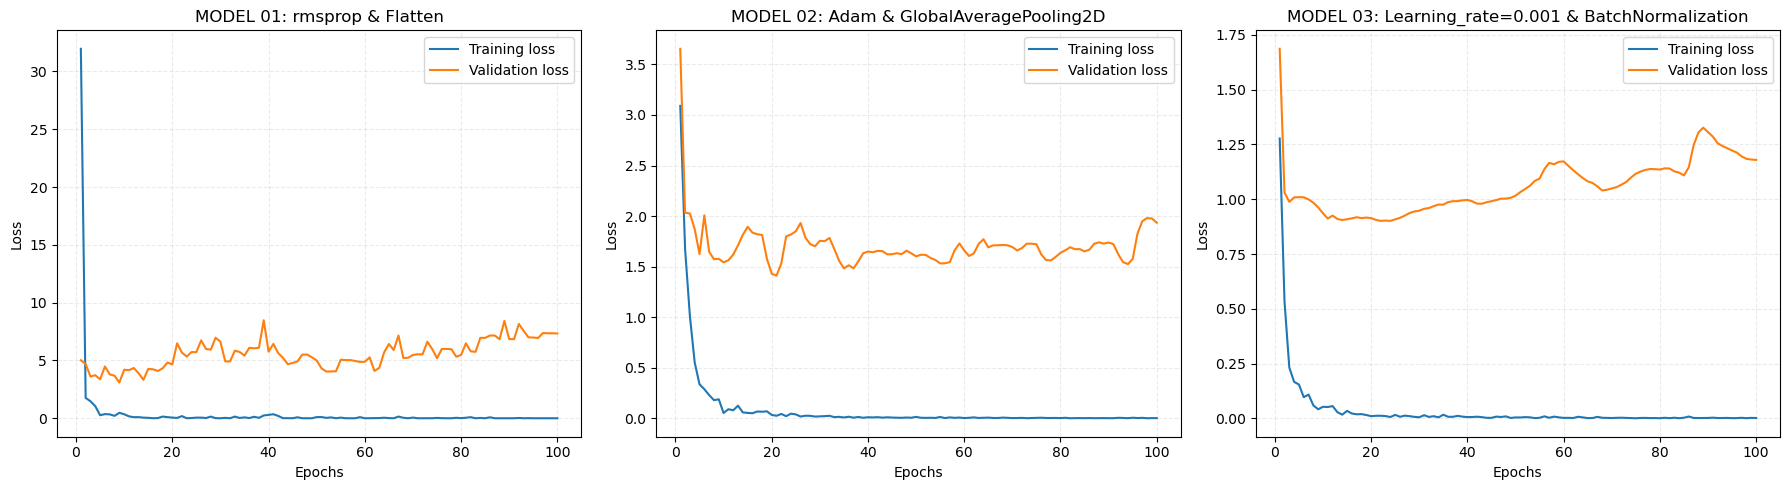

In [119]:
ig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# model 1
epochs_1 = list(range(1, len(history_01.history["loss"]) + 1))
ax1.plot(epochs_1, history_01.history["loss"], label="Training loss")
ax1.plot(epochs_1, history_01.history["val_loss"], label="Validation loss")
ax1.set_title("MODEL 01: rmsprop & Flatten")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.25)


# model 2
epochs_2 = list(range(1, len(history_02.history["loss"]) + 1))
ax2.plot(epochs_2, history_02.history["loss"], label="Training loss")
ax2.plot(epochs_2, history_02.history["val_loss"], label="Validation loss")
ax2.set_title("MODEL 02: Adam & GlobalAveragePooling2D")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.25)

#model 3
epochs_3 = list(range(1, len(history_03.history["loss"]) + 1))
ax3.plot(epochs_3, history_03.history["loss"], label="Training loss")
ax3.plot(epochs_3, history_03.history["val_loss"], label="Validation loss")
ax3.set_title("MODEL 03: Learning_rate=0.001 & BatchNormalization")
ax3.set_xlabel("Epochs")
ax3.set_ylabel("Loss")
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.25)

plt.tight_layout()
plt.show()

All of the trained models learn very well from the training data, but perform poorly on the validation data. <b>Three different approaches were utilized to minimize overfitting, but success could not be achieved</b>.

| Model | Training Data | Validation | Generalization |
|---|---|---|---|
| Model 01 | Great | Weak | Weak |
| Model 02 | Great | Moderate | Limited |
| Model 03 | Great | Best of three | Best of three 

This table was constructed to interpret the three models based on their loss plots. Unfortunately, the hypothesis was proven correct, and given the current amount of data, overfitting cannot be fully tackled.

<h2>5. Evaluation</h2>

In [120]:
accuracy = history_03.history["accuracy"]
val_accuracy = history_03.history["val_accuracy"]
loss = history_03.history["loss"]
val_loss = history_03.history["val_loss"]
epochs = list(range(1, len(accuracy)+1)) 

test_loss, test_acc = model_03.evaluate(test_features, test_labels)

print('Test accuracy: ', test_acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7170 - loss: 1.1939
Test accuracy:  0.7169811129570007


Accuracy of our created model with test dataset tells us that it could predict only $\approx$72% of new data that it has never seen.
This confirms that the model truly is overfitted, because it gave us 100% accuracy on training data.

In [121]:
model_03.summary()

Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d_30     │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 398,347 (1.52 MB)

 Trainable params: 132,611 (518.01 KB)

 Non-trainable params: 512 (2.00 KB)

 Optimizer params: 265,224 (1.01 MB)

This represents the custom classifier stack through which the extracted features are processed. It consists of 5 layers and remains relatively simple.

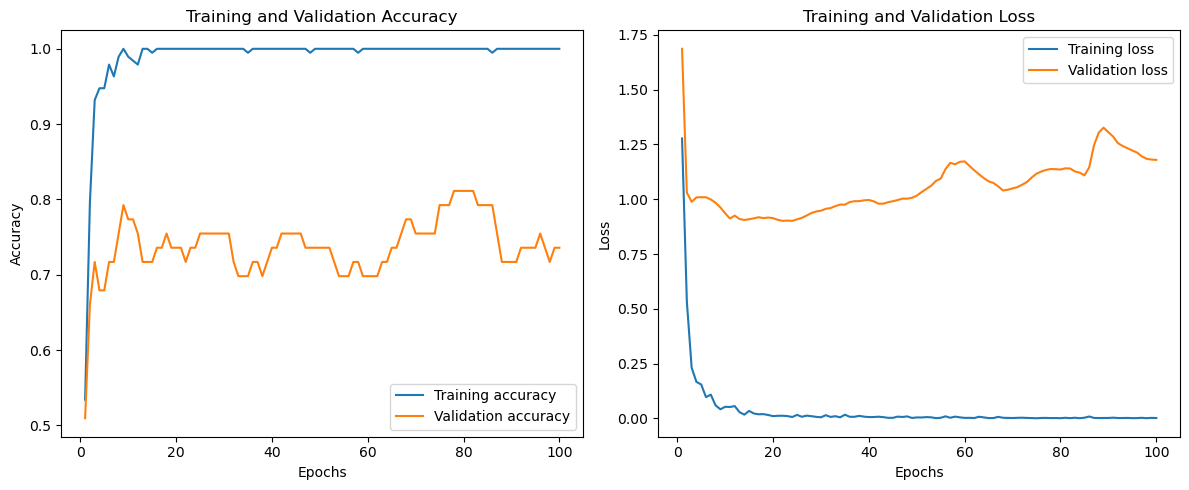

In [122]:
fig, (acc, loss_plt) = plt.subplots(1, 2, figsize=(12, 5))

# ACC PLOT
acc.plot(epochs, accuracy, label="Training accuracy")
acc.plot(epochs, val_accuracy, label="Validation accuracy")
acc.set_title("Training and Validation Accuracy")
acc.set_xlabel("Epochs")
acc.set_ylabel("Accuracy")
acc.legend()

# LOSS PLOT
loss_plt.plot(epochs, loss, label="Training loss")
loss_plt.plot(epochs, val_loss, label="Validation loss")
loss_plt.set_title("Training and Validation Loss")
loss_plt.set_xlabel("Epochs")
loss_plt.set_ylabel("Loss")
loss_plt.legend()

plt.tight_layout()
plt.show()

Plots above are the chosen Model 03 accuracy and loss; this model performed best.

- <b>Accuracy</b>: Training accuracy rises fast to nearly 100% and stays there. Validation accuracy, on the other hand, stays between 70–80%.
- <b>Loss</b>: Training loss decreases to zero, but validation loss starts to fluctuate after 40 epochs.

<h4>Conclusion:</h4>
Both plots indicate strong overfitting. The model learns the training data by heart, but generalization to new unseen data is limited. This supports the earlier hypothesis that the VGG16 architecture is too complex for this small dataset.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


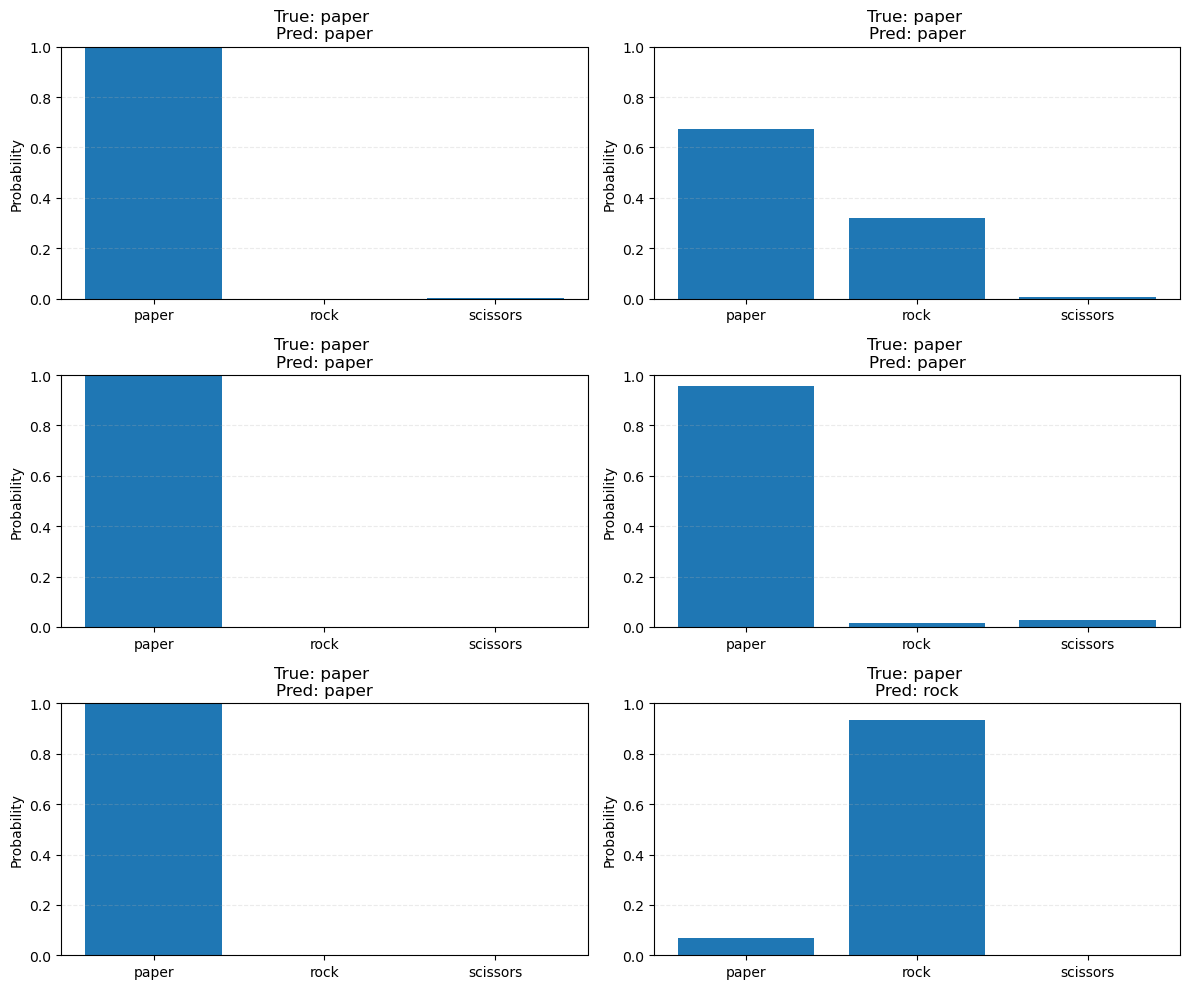

In [126]:
class_names = test_dataset.class_names
probs = model_03.predict(test_features)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
axes = axes.flatten()

for i in range(6):
    true_label = int(test_labels[i])
    pred_label = np.argmax(probs[i])
    
    ax = axes[i]
    ax.bar(class_names, probs[i])
    ax.set_title(f"True: {class_names[true_label]} \nPred: {class_names[pred_label]}")
    ax.set_ylabel("Probability")
    ax.set_ylim(0, 1)
    ax.grid(axis='y', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

The diagrams above show the classification certainties for the first six test samples.

<b>First five samples:</b> Classified correctly, and in each case the model is quite confident in its prediction (near 1.0).</br>
<b>Last sample:</b> Predicted incorrectly, the model misclassified the paper image as rock with high confidence (around 94%).

Although the model performs well on many test images, it occasionally makes errors.

<h2>6. Deployment</h2>

This is not the most optimal approach for our current dataset. Utilizing this approach would require significantly more data to perform correctly. The model is overfitted and cannot make accurate predictions on unseen data, making it unsuitable for deployment.